# Extra variables in the GermanBight hindcast

Checks which variables appear in which hindcast files, and looks at the variables that are only
in some of them. Sections 1–3 only read file metadata, so they are fast. Section 4 reads a little data.

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import netCDF4
import matplotlib.pyplot as plt
from matplotlib.tri import Triangulation

HINDCAST_DIR = Path('/hpcfreenas/hindcast/Europe/GermanBight')

## 1. Variables in every file

Each file is named `<type>_<day>.nc`. The table has one row per file and one column per
variable; `True` means the variable is in that file.

In [2]:
rows = []
for f in sorted(HINDCAST_DIR.glob('*.nc')):
    ftype, day = re.fullmatch(r'(.+)_(\d+)\.nc', f.name).groups()
    with netCDF4.Dataset(f) as ds:
        rows.append(dict(file=f.name, type=ftype, day=int(day), variables=set(ds.variables)))
files = pd.DataFrame(rows).sort_values(['type', 'day']).reset_index(drop=True)

all_vars = sorted(set().union(*files['variables']))
presence = pd.DataFrame([[v in s for v in all_vars] for s in files['variables']],
                        columns=all_vars, index=pd.MultiIndex.from_frame(files[['type', 'day']]))
print(f'{len(files)} files, {files["type"].nunique()} file types, days {files["day"].min()}–{files["day"].max()}, '
      f'{len(all_vars)} distinct variable names')

330 files, 11 file types, days 1–30, 71 distinct variable names


## 2. Is the variable set constant within each file type?

For each file type: how many different variable sets occur, and on which days the set changes.

In [3]:
summary = []
for ftype, g in presence.groupby(level='type'):
    sets = g.apply(lambda r: frozenset(r.index[r.values]), axis=1)
    days = g.index.get_level_values('day')
    changes = [int(days[i]) for i in range(1, len(sets)) if sets.iloc[i] != sets.iloc[i - 1]]
    summary.append(dict(type=ftype, files=len(g), distinct_variable_sets=sets.nunique(),
                        n_vars_min=min(len(s) for s in sets), n_vars_max=max(len(s) for s in sets),
                        set_changes_on_day=changes))
pd.DataFrame(summary).set_index('type')

,files,distinct_variable_sets,n_vars_min,n_vars_max,set_changes_on_day
type,,,,,
diffusivity,30,1,2,2,[]
horizontalVelX,30,1,2,2,[]
horizontalVelY,30,1,2,2,[]
out2d,30,2,43,61,[22]
salinity,30,1,2,2,[]
temperature,30,1,2,2,[]
turbulentKineticEner,30,1,2,2,[]
verticalVelocity,30,1,2,2,[]
viscosity,30,1,2,2,[]


## 3. Variables that are not in every file of their type

For each such variable: its file type and the days it is present. A variable listed under one file
type is in none of the other types' files.

In [4]:
partial = []
for ftype, g in presence.groupby(level='type'):
    g = g.loc[:, g.any()]                      # variables used by this file type
    for v in g.columns[~g.all()]:
        days = g.index.get_level_values('day')[g[v].values]
        partial.append(dict(variable=v, type=ftype, n_files=len(days),
                            present_days=f'{days.min()}–{days.max()}',
                            contiguous=bool(np.all(np.diff(days) == 1)),
                            in_other_file_types=sorted(set(presence.index[presence[v]].get_level_values('type')) - {ftype})))
partial = pd.DataFrame(partial)
partial

,variable,type,n_files,present_days,contiguous,in_other_file_types
0,CharnockCoeff,out2d,9,22–30,True,[]
1,UresellNumber,out2d,9,22–30,True,[]
2,bottomExcursionPerio,out2d,9,22–30,True,[]
3,bottomWavePeriod,out2d,9,22–30,True,[]
4,continuousPeakPeriod,out2d,9,22–30,True,[]
5,discretePeakDirectio,out2d,9,22–30,True,[]
6,dissRateDepBreaking,out2d,9,22–30,True,[]
7,dominantDirection,out2d,9,22–30,True,[]
8,orbitalVelocity,out2d,9,22–30,True,[]
9,peakGroupVel,out2d,9,22–30,True,[]


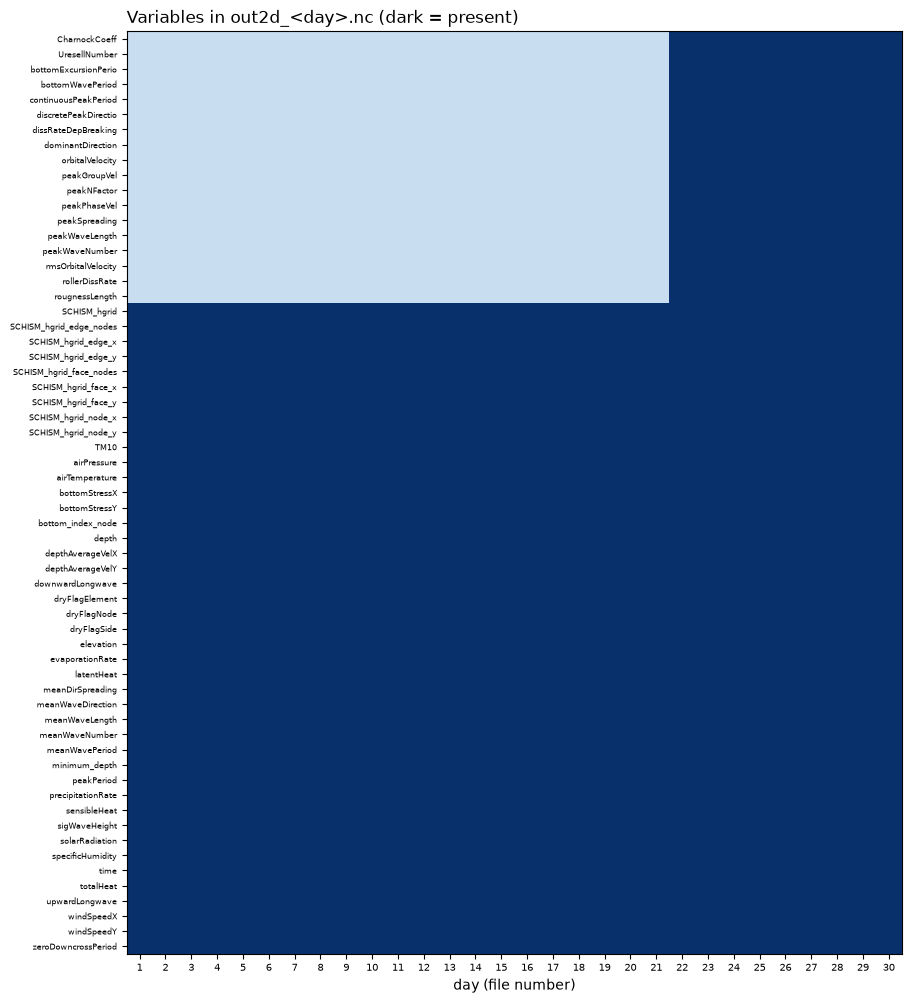

In [5]:
# presence matrix for out2d: rows = variables, columns = day of file; blue = present
o = presence.xs('out2d', level='type')
o = o.loc[:, o.any()]
o = o[sorted(o.columns, key=lambda v: (o[v].all(), v))]   # partial variables first

fig, ax = plt.subplots(figsize=(10, 0.18 * o.shape[1] + 1))
ax.imshow(o.T.values, aspect='auto', cmap='Blues', vmin=-0.3, vmax=1, interpolation='nearest')
ax.set_yticks(range(o.shape[1]), o.columns, fontsize=6)
ax.set_xticks(range(o.shape[0]), o.index, fontsize=7)
ax.set_xlabel('day (file number)')
ax.set_title('Variables in out2d_<day>.nc (dark = present)', loc='left');

## 4. Do the extra variables hold real data?

Pick one extra variable and file: the map shows it at one time step, and the line shows its
domain mean for every time step of the days it exists. Missing days have no line.

peakWaveLength in out2d_22.nc, step 12: min 0, max 205, 10% zeros, 0% NaN


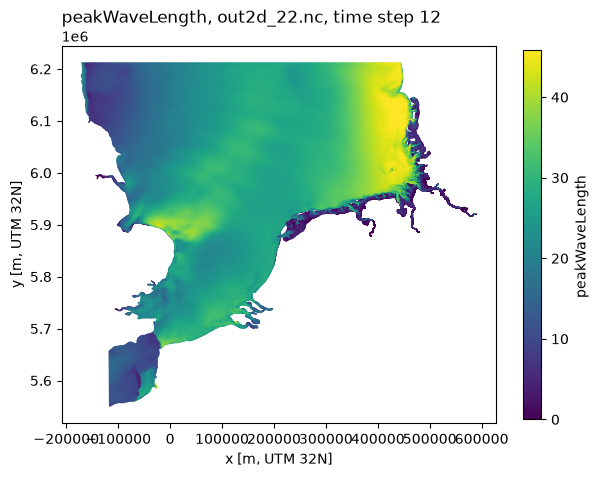

In [6]:
VAR = 'peakWaveLength'      # any name from the table in section 3
DAY = int(partial.set_index('variable').loc[VAR, 'present_days'].split('–')[0])
STEP = 12                   # time step within the file

with netCDF4.Dataset(HINDCAST_DIR / f'out2d_{DAY}.nc') as ds:
    x, y = ds['SCHISM_hgrid_node_x'][:], ds['SCHISM_hgrid_node_y'][:]
    tri = np.asarray(ds['SCHISM_hgrid_face_nodes'][:, :3], dtype=int) - 1
    data = np.ma.filled(ds[VAR][STEP].astype(float), np.nan)
    units = getattr(ds[VAR], 'units', '')
print(f'{VAR} in out2d_{DAY}.nc, step {STEP}: min {np.nanmin(data):.3g}, max {np.nanmax(data):.3g}, '
      f'{np.mean(data == 0):.0%} zeros, {np.mean(np.isnan(data)):.0%} NaN')

fig, ax = plt.subplots(figsize=(7, 6))
tc = ax.tripcolor(Triangulation(x, y, tri), data, shading='gouraud', cmap='viridis',
                  vmin=np.nanpercentile(data, 1), vmax=np.nanpercentile(data, 99))   # clip outliers
fig.colorbar(tc, ax=ax, shrink=0.8, label=f'{VAR} {units}')
ax.set_aspect('equal')
ax.set_xlabel('x [m, UTM 32N]')
ax.set_ylabel('y [m, UTM 32N]')
ax.set_title(f'{VAR}, out2d_{DAY}.nc, time step {STEP}', loc='left');

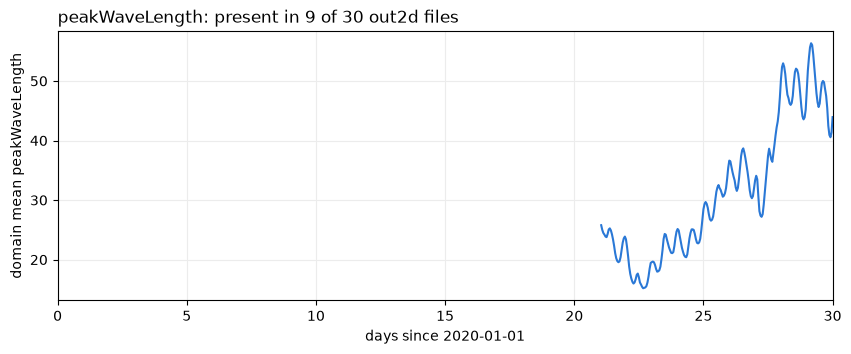

In [7]:
t_all, m_all = [], []
for day in sorted(files.loc[files['type'] == 'out2d', 'day']):
    with netCDF4.Dataset(HINDCAST_DIR / f'out2d_{day}.nc') as ds:
        if VAR not in ds.variables:
            continue
        t_all.append(ds['time'][:] / 86400.)
        m_all.append(np.nanmean(np.ma.filled(ds[VAR][:].astype(float), np.nan), axis=1))

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(np.concatenate(t_all), np.concatenate(m_all), color='#2a78d6')   # files are consecutive hours
ax.set_xlim(0, files['day'].max())
ax.set_xlabel('days since 2020-01-01')
ax.set_ylabel(f'domain mean {VAR}')
ax.set_title(f'{VAR}: present in {len(t_all)} of {files.loc[files["type"] == "out2d"].shape[0]} out2d files', loc='left')
ax.grid(color='#ececec');